<a href="https://colab.research.google.com/github/akatwrk/DeeplearningExp/blob/main/exp9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, GRU, Dense, Dropout

from sklearn.metrics import confusion_matrix, classification_report

In [2]:
sample_reviews = [

    "This movie is fantastic",

    "I loved this movie",

    "Worst movie ever",

    "The acting was amazing",

    "The film was boring"

]


In [3]:
tokenizer = Tokenizer(num_words=10000)

tokenizer.fit_on_texts(sample_reviews)

print("Word Index:\n")

print(tokenizer.word_index)

print("\nTokenized Sequences:\n")

sequences = tokenizer.texts_to_sequences(sample_reviews)

print(sequences)

Word Index:

{'movie': 1, 'this': 2, 'the': 3, 'was': 4, 'is': 5, 'fantastic': 6, 'i': 7, 'loved': 8, 'worst': 9, 'ever': 10, 'acting': 11, 'amazing': 12, 'film': 13, 'boring': 14}

Tokenized Sequences:

[[2, 1, 5, 6], [7, 8, 2, 1], [9, 1, 10], [3, 11, 4, 12], [3, 13, 4, 14]]


In [4]:
padded = pad_sequences(sequences, maxlen=6, padding='post')
print("Padded Sequences:\n")
print(padded)

vocab_size = 10000
(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

Padded Sequences:

[[ 2  1  5  6  0  0]
 [ 7  8  2  1  0  0]
 [ 9  1 10  0  0  0]
 [ 3 11  4 12  0  0]
 [ 3 13  4 14  0  0]]
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [5]:
print("Training Samples :", X_train.shape)
print("Testing Samples :", X_test.shape)

Training Samples : (25000,)
Testing Samples : (25000,)


In [6]:
print("First Review (Encoded)\n")
print(X_train[0])
print("\nLength of Review :", len(X_train[0]))
print("\nSentiment Label :", y_train[0])

First Review (Encoded)

[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]

Length of Review : 218

Sentiment L

In [7]:
word_index = imdb.get_word_index()
reverse_word_index = {
value + 3: key
for (key, value) in word_index.items()
}
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"
reverse_word_index[3] = "<UNUSED>"
decoded_review = " ".join(
reverse_word_index.get(i, "?")
for i in X_train[0]
)
print(decoded_review)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out of the <UNK> list i think because the stars that play them all grown up are such a big profile for the whole film but these c

In [8]:
max_length = 200
X_train = pad_sequences(
X_train,
maxlen=max_length,
padding="post",
truncating="post"
)
X_test = pad_sequences(
X_test,
maxlen=max_length,
padding="post",
truncating="post"
)
print(X_train.shape)
print(X_test.shape)
(25000, 200)
(25000, 200)
print("First Review Shape :", X_train[0].shape)
print("First 30 Tokens:\n")
print(X_train[0][:30])

print("\nSentiment :", y_train[0])

(25000, 200)
(25000, 200)
First Review Shape : (200,)
First 30 Tokens:

[   1   14   22   16   43  530  973 1622 1385   65  458 4468   66 3941
    4  173   36  256    5   25  100   43  838  112   50  670    2    9
   35  480]

Sentiment : 1


In [9]:
  embedding_dim = 128

lstm_model = Sequential([

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        input_length=max_length
    ),

    LSTM(128),

    Dropout(0.5),

    Dense(64, activation="relu"),

    Dense(1, activation="sigmoid")

])

lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
lstm_model.compile(
optimizer="adam",
loss="binary_crossentropy",
metrics=["accuracy"]
)

In [11]:
history_lstm = lstm_model.fit(
X_train,
y_train,
validation_data=(X_test, y_test),
epochs=5,
batch_size=64,
verbose=1
)

Epoch 1/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 159s 403ms/step - accuracy: 0.5321 - loss: 0.6925 - val_accuracy: 0.5809 - val_loss: 0.6637
Epoch 2/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 146s 373ms/step - accuracy: 0.5860 - loss: 0.6625 - val_accuracy: 0.5376 - val_loss: 0.6808
Epoch 3/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 149s 380ms/step - accuracy: 0.6300 - loss: 0.6399 - val_accuracy: 0.5000 - val_loss: 0.6971
Epoch 4/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 211s 403ms/step - accuracy: 0.5348 - loss: 0.6862 - val_accuracy: 0.5493 - val_loss: 0.6801
Epoch 5/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 191s 375ms/step - accuracy: 0.6826 - loss: 0.5693 - val_accuracy: 0.8224 - val_loss: 0.4186


In [12]:
loss_lstm, accuracy_lstm = lstm_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("LSTM Test Loss :", loss_lstm)
print("LSTM Test Accuracy :", accuracy_lstm)

LSTM Test Loss : 0.4185938537120819
LSTM Test Accuracy : 0.8223999738693237


In [13]:
gru_model = Sequential([

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        input_length=max_length
    ),

    GRU(128),

    Dropout(0.5),

    Dense(64, activation="relu"),

    Dense(1, activation="sigmoid")

])

gru_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [14]:
gru_model.compile(
optimizer="adam",
loss="binary_crossentropy",
metrics=["accuracy"]
)
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(
monitor="val_loss",
patience=2,
restore_best_weights=True
)
history_gru = gru_model.fit(
X_train,
y_train,
validation_data=(X_test, y_test),
epochs=10,
batch_size=64,
callbacks=[early_stop]
)

Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 129s 324ms/step - accuracy: 0.5174 - loss: 0.6923 - val_accuracy: 0.5160 - val_loss: 0.6936
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 127s 324ms/step - accuracy: 0.6290 - loss: 0.6251 - val_accuracy: 0.7773 - val_loss: 0.5734
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 127s 324ms/step - accuracy: 0.8614 - loss: 0.3395 - val_accuracy: 0.8551 - val_loss: 0.3295
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 141s 361ms/step - accuracy: 0.9276 - loss: 0.2017 - val_accuracy: 0.8558 - val_loss: 0.3592
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 126s 322ms/step - accuracy: 0.9617 - loss: 0.1228 - val_accuracy: 0.8484 - val_loss: 0.4076


In [16]:
loss_gru, accuracy_gru = gru_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("GRU Test Loss :", loss_gru)
print("GRU Test Accuracy :", accuracy_gru)

GRU Test Loss : 0.3295195400714874
GRU Test Accuracy : 0.8550800085067749


In [17]:
loss_gru, accuracy_gru = gru_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("GRU Test Loss :", loss_gru)
print("GRU Test Accuracy :", accuracy_gru)

GRU Test Loss : 0.3295195400714874
GRU Test Accuracy : 0.8550800085067749


In [18]:

import pandas as pd

comparison = pd.DataFrame({

    "Model": ["LSTM", "GRU"],

    "Loss": [loss_lstm, loss_gru],

    "Accuracy": [accuracy_lstm, accuracy_gru]

})

print(comparison)

  Model      Loss  Accuracy
0  LSTM  0.418594   0.82240
1   GRU  0.329520   0.85508


In [19]:
y_pred_lstm = lstm_model.predict(X_test)

y_pred_lstm = (y_pred_lstm > 0.5).astype(int)

print("LSTM Prediction Shape:", y_pred_lstm.shape)

782/782 ━━━━━━━━━━━━━━━━━━━━ 44s 56ms/step
LSTM Prediction Shape: (25000, 1)


In [20]:
y_pred_gru = gru_model.predict(X_test)

y_pred_gru = (y_pred_gru > 0.5).astype(int)

print("GRU Prediction Shape:", y_pred_gru.shape)

782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 30ms/step
GRU Prediction Shape: (25000, 1)


[[ 9607  2893]
 [ 1547 10953]]


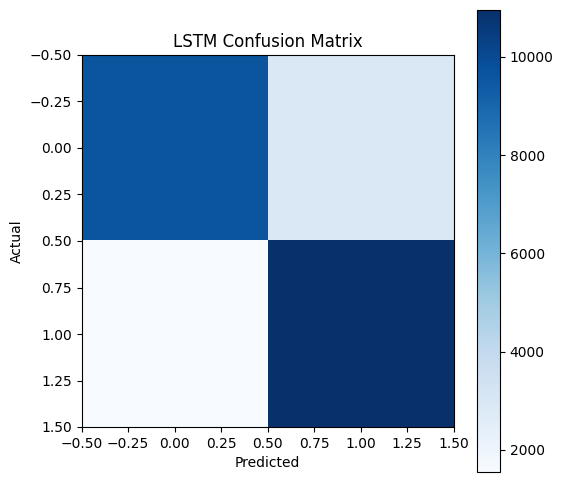

In [21]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
cm_lstm = confusion_matrix(y_test, y_pred_lstm)
print(cm_lstm)
plt.figure(figsize=(6,6))
plt.imshow(cm_lstm, cmap="Blues")
plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

[[11317  1183]
 [ 2440 10060]]


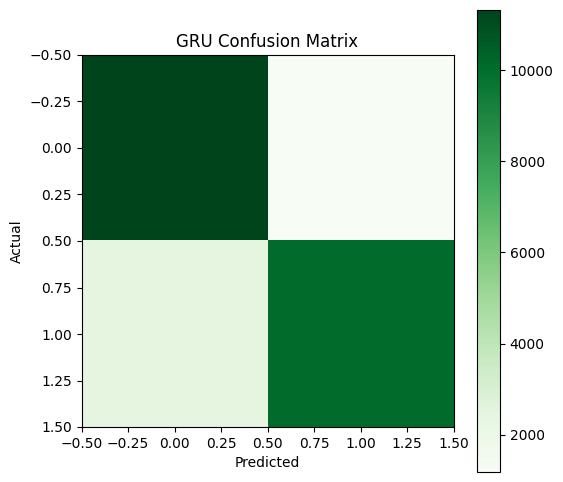

In [22]:
cm_gru = confusion_matrix(y_test, y_pred_gru)
print(cm_gru)
plt.figure(figsize=(6,6))
plt.imshow(cm_gru, cmap="Greens")
plt.title("GRU Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

In [23]:
from sklearn.metrics import classification_report
print("========== LSTM ==========")
print(classification_report(
y_test,
y_pred_lstm,
    target_names=["Negative","Positive"]
))

print("\n========== GRU ==========")

print(classification_report(
    y_test,
    y_pred_gru,
    target_names=["Negative","Positive"]
))

========== LSTM ==========
              precision    recall  f1-score   support

    Negative       0.86      0.77      0.81     12500
    Positive       0.79      0.88      0.83     12500

    accuracy                           0.82     25000
   macro avg       0.83      0.82      0.82     25000
weighted avg       0.83      0.82      0.82     25000


========== GRU ==========
              precision    recall  f1-score   support

    Negative       0.82      0.91      0.86     12500
    Positive       0.89      0.80      0.85     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.85     25000
weighted avg       0.86      0.86      0.85     25000



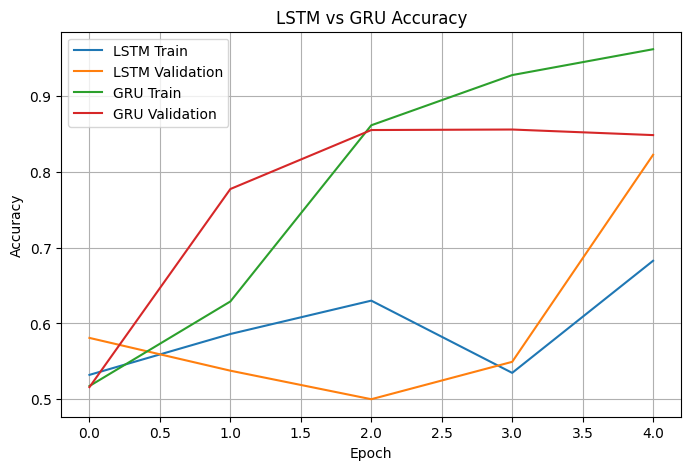

In [24]:
plt.figure(figsize=(8,5))

plt.plot(history_lstm.history["accuracy"],
         label="LSTM Train")

plt.plot(history_lstm.history["val_accuracy"],
         label="LSTM Validation")

plt.plot(history_gru.history["accuracy"],
         label="GRU Train")

plt.plot(history_gru.history["val_accuracy"],
         label="GRU Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM vs GRU Accuracy")
plt.legend()
plt.grid(True)
plt.show()

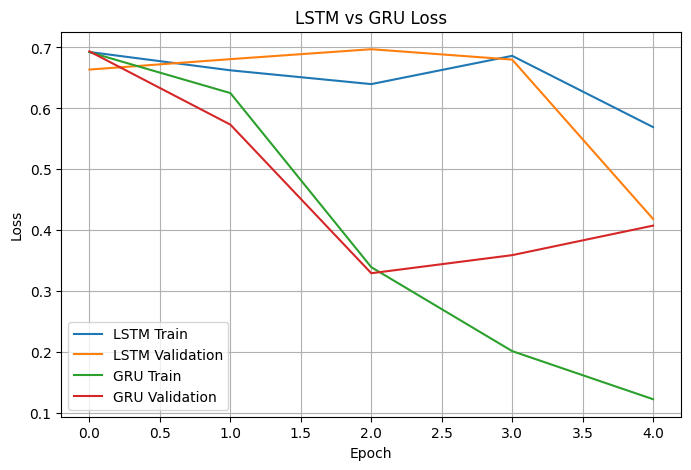

In [25]:
plt.figure(figsize=(8,5))
plt.plot(history_lstm.history["loss"],
label="LSTM Train")
plt.plot(history_lstm.history["val_loss"],
label="LSTM Validation")
plt.plot(history_gru.history["loss"],
label="GRU Train")
plt.plot(history_gru.history["val_loss"],
label="GRU Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM vs GRU Loss")
plt.legend()
plt.grid(True)
plt.show()


In [26]:
print("LSTM Training Loss:", len(history_lstm.history["loss"]))
print("LSTM Validation Loss:", len(history_lstm.history["val_loss"]))
print("GRU Training Loss:", len(history_gru.history["loss"]))
print("GRU Validation Loss:", len(history_gru.history["val_loss"]))

LSTM Training Loss: 5
LSTM Validation Loss: 5
GRU Training Loss: 5
GRU Validation Loss: 5
